# Oracle Construction — Boolean Oracle — CUDA-Q Notebook

**Primitive:** general Boolean-formula oracle for `f(x0,x1,x2) = (x0 AND x1) XOR x2`,
compiled with the "compute - copy - uncompute" pattern (Toffoli for `AND`, `CNOT`s for
`XOR`, uncompute the ancilla).

This notebook is the CUDA-Q counterpart to `bool_oracle_qiskit.ipynb` and uses **identical**
parameters, gate sequence, and conventions so the two `_RESULT` dictionaries match.

## SETUP (identical to the Qiskit notebook)
| Parameter | Value |
|---|---|
| N_QUBITS (input register) | 3  (x0, x1, x2 — indices q0..q2, q0 = LSB) |
| ANCILLA_QUBIT | q3  (scratch qubit for `x0 AND x1`) |
| OUTPUT_QUBIT | q4  (accumulates `f(x0,x1,x2)`) |
| TOTAL_QUBITS | 5 |
| Boolean function | `f(x0,x1,x2) = (x0 AND x1) XOR x2` |
| SHOTS | 10000 |
| SEED | 42 |
| QUBIT ORDERING CONTRACT | qubit 0 = **rightmost** bit in every printed bitstring. `cudaq.get_state()`'s returned array is **already** in this convention (no reversal needed); only `cudaq.sample()`'s bitstring keys need reversing. |
| GLOBAL PHASE CONVENTION | normalize so the first amplitude with `abs(amp) > 1e-9`, taken in ascending bitstring order, is rotated to be real and positive |
| Basis ordering for matrices | `{|00000>, |00001>, ..., |11111>}` ascending binary order (32-dim, 5 qubits) |

## Theory recap

Same as the Qiskit notebook:

```
Toffoli(q0, q1 -> ANCILLA)     # ancilla = x0 AND x1
CNOT(ANCILLA -> OUTPUT)         # output ^= (x0 AND x1)
CNOT(q2 -> OUTPUT)              # output ^= x2  -> output = f(x0,x1,x2)
Toffoli(q0, q1 -> ANCILLA)     # uncompute: ancilla back to |0>
```

**Test harness:** `H` on the 3 input qubits only. As proven in the Qiskit notebook, exactly
8 of the 32 possible 5-qubit outcomes are reachable, each at probability `1/8`.

## ⚠️ Ordering-convention warning (corrected)

CUDA-Q's `cudaq.sample()` returns bitstring keys with **qubit 0 as the leftmost character**
(the opposite of Qiskit) -- those keys are explicitly reversed before comparison.

`cudaq.get_state()`, however, when converted to a NumPy array via `np.array(...)`, returns
amplitudes indexed with **qubit 0 already as the least-significant bit** -- the *same*
convention Qiskit uses. An earlier version of this notebook incorrectly applied the same
bit-reversal to the statevector as to the sample counts; that reversal permuted the
amplitudes onto the wrong basis states and is why the exact-statevector result disagreed
with the Qiskit notebook and with the hand-computed truth table (the sampled-counts result
was never affected, since that reversal was correct). This version removes the erroneous
statevector reversal.

## Environment note

CUDA-Q's Python wheel (`cudaq`) ships for **Linux (x86_64 / aarch64)**, Python 3.10-3.12,
CPU simulator by default (`cudaq.set_target("qpp-cpu")`) -- no GPU required. On
Windows/macOS use the official `nvcr.io/nvidia/cuda-quantum` Docker image.

**Run all cells top to bottom.**


In [1]:
# Install cell
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 87.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 96.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 6.4 MB/s eta 0:00:

In [2]:
# Imports + constants (identical values to the Qiskit notebook)
import numpy as np
from math import pi
import cudaq
import matplotlib.pyplot as plt

N_QUBITS = 3
ANCILLA_QUBIT = 3
OUTPUT_QUBIT = 4
TOTAL_QUBITS = 5
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "bool_oracle"

def f_boolean(x0, x1, x2):
    return (x0 & x1) ^ x2

cudaq.set_target("qpp-cpu")
cudaq.set_random_seed(SEED)

print("N_QUBITS      =", N_QUBITS)
print("ANCILLA_QUBIT =", ANCILLA_QUBIT)
print("OUTPUT_QUBIT  =", OUTPUT_QUBIT)
print("TOTAL_QUBITS  =", TOTAL_QUBITS)
print("SHOTS         =", SHOTS)
print("SEED          =", SEED)
print("Target        =", cudaq.get_target().name)


N_QUBITS      = 3
ANCILLA_QUBIT = 3
OUTPUT_QUBIT  = 4
TOTAL_QUBITS  = 5
SHOTS         = 10000
SEED          = 42
Target        = qpp-cpu


In [3]:
# Build the kernel gate-by-gate
# NOTE: qubits[0..2] = x0,x1,x2 (input), qubits[3] = ancilla (x0 AND x1), qubits[4] = output.
# CUDA-Q's native `cx` gate is used for CNOT; `x.ctrl(c0, c1, target)` is used for the Toffoli
# (matches the pattern established in the earlier bit-flip / arithmetic oracle notebooks).

@cudaq.kernel
def bool_oracle_kernel():
    qubits = cudaq.qvector(5)  # TOTAL_QUBITS hardcoded to 5 inside the kernel (must be a literal)

    h(qubits[0]); h(qubits[1]); h(qubits[2])   # test harness: uniform superposition over inputs

    x.ctrl(qubits[0], qubits[1], qubits[3])     # Toffoli: ancilla = x0 AND x1
    cx(qubits[3], qubits[4])                     # CNOT: output ^= ancilla
    cx(qubits[2], qubits[4])                     # CNOT: output ^= x2  -> output = f(x0,x1,x2)
    x.ctrl(qubits[0], qubits[1], qubits[3])     # uncompute: ancilla back to |0>

# Mirror the same gate list in plain Python (used for resource counts, the matplotlib
# circuit diagram, and the hand-built matrix cross-check below) so it stays in lockstep
# with the kernel body above by construction.
gatelist = [('H', q) for q in range(N_QUBITS)]
gatelist.append(('MCX', [0, 1], ANCILLA_QUBIT))
gatelist.append(('MCX', [ANCILLA_QUBIT], OUTPUT_QUBIT))
gatelist.append(('MCX', [2], OUTPUT_QUBIT))
gatelist.append(('MCX', [0, 1], ANCILLA_QUBIT))

print("Gate list (", len(gatelist), "gates ) matches the kernel body above.")


Gate list ( 7 gates ) matches the kernel body above.


     ╭───╮                    
q0 : ┤ h ├──●──────────────●──
     ├───┤  │              │  
q1 : ┤ h ├──●──────────────●──
     ├───┤  │              │  
q2 : ┤ h ├──┼─────────●────┼──
     ╰───╯╭─┴─╮       │  ╭─┴─╮
q3 : ─────┤ x ├──●────┼──┤ x ├
          ╰───╯╭─┴─╮╭─┴─╮╰───╯
q4 : ──────────┤ x ├┤ x ├─────
               ╰───╯╰───╯     



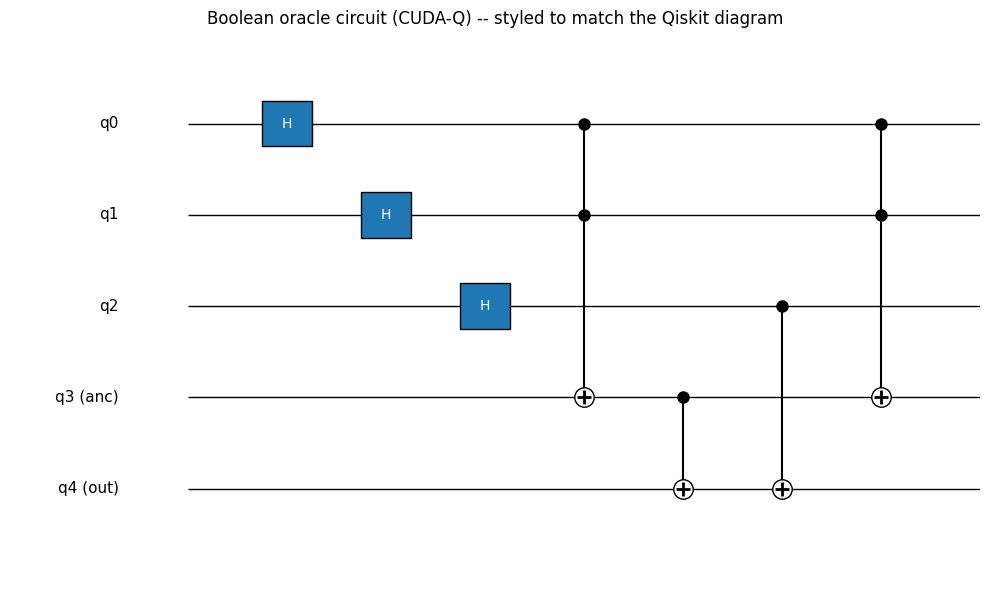

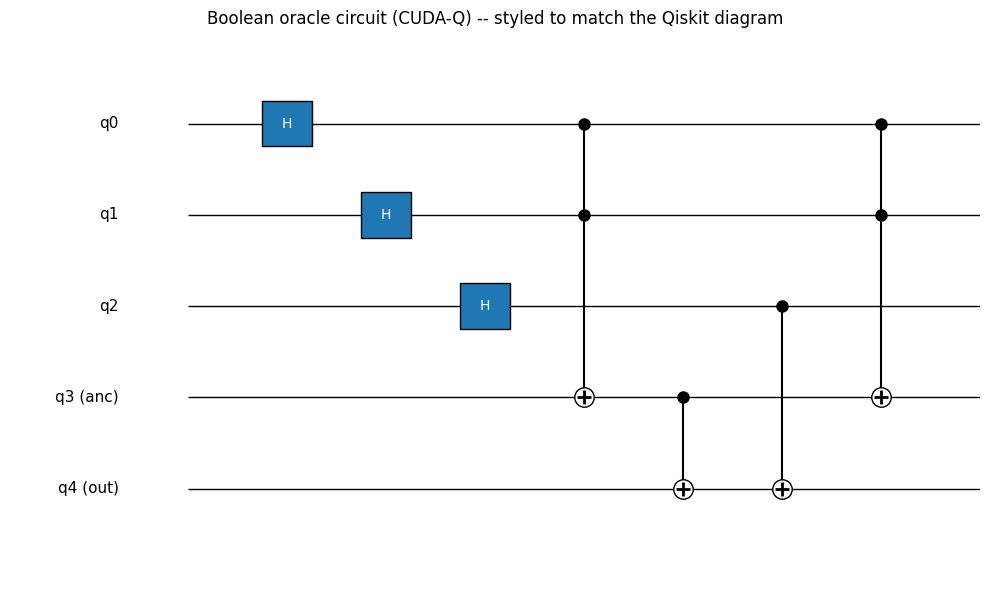

In [4]:
# Draw the circuit: cudaq's own text diagram, then a matplotlib figure styled like Qiskit's
print(cudaq.draw(bool_oracle_kernel))

fig, ax = plt.subplots(figsize=(10, 6))
n_wires = TOTAL_QUBITS
wire_y = {q: n_wires - 1 - q for q in range(n_wires)}

col = 0
col_positions = {}
for gate in gatelist:
    col += 1
    col_positions[id(gate)] = col
n_cols = col + 1

for q in range(n_wires):
    label = f"q{q}"
    if q == ANCILLA_QUBIT:
        label += " (anc)"
    if q == OUTPUT_QUBIT:
        label += " (out)"
    ax.hlines(wire_y[q], 0, n_cols, color="black", linewidth=1, zorder=1)
    ax.text(-0.7, wire_y[q], label, va="center", ha="right", fontsize=11)

for gate in gatelist:
    x_pos = col_positions[id(gate)]
    if gate[0] == 'H':
        _, q = gate
        ax.add_patch(plt.Rectangle((x_pos - 0.25, wire_y[q] - 0.25), 0.5, 0.5, facecolor="#1f77b4", edgecolor="black", zorder=2))
        ax.text(x_pos, wire_y[q], "H", ha="center", va="center", fontsize=10, color="white", zorder=3)
    elif gate[0] == 'MCX':
        _, controls, target = gate
        all_q = controls + [target]
        ax.vlines(x_pos, wire_y[min(all_q)], wire_y[max(all_q)], color="black", zorder=2)
        for c in controls:
            ax.plot(x_pos, wire_y[c], marker="o", color="black", markersize=8, zorder=3)
        ax.plot(x_pos, wire_y[target], marker="o", color="white", markeredgecolor="black", markersize=14, zorder=3)
        ax.plot(x_pos, wire_y[target], marker="+", color="black", markersize=10, mew=2, zorder=4)

ax.set_xlim(-1.8, n_cols)
ax.set_ylim(-1, n_wires)
ax.axis("off")
ax.set_title("Boolean oracle circuit (CUDA-Q) -- styled to match the Qiskit diagram")
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation, built two independent ways, cross-checked
# CUDA-Q has no dense-operator-extraction API, so the cross-check here is against
# CUDA-Q's own statevector simulation (cudaq.get_state), applied to |00000>.

def h_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        bit = (idx >> q) & 1
        idx0 = idx & ~(1 << q); idx1 = idx | (1 << q)
        if bit == 0:
            M[idx0, idx] += 1/np.sqrt(2); M[idx1, idx] += 1/np.sqrt(2)
        else:
            M[idx1, idx] += -1/np.sqrt(2); M[idx0, idx] += 1/np.sqrt(2)
    return M

def mcx_matrix_full(n, controls, target):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        if all((idx >> c) & 1 for c in controls):
            M[idx ^ (1 << target), idx] = 1
        else:
            M[idx, idx] = 1
    return M

print("Toffoli (x.ctrl with 2 controls) and CNOT (x.ctrl with 1 control) are both permutation")
print("matrices -- built here with the same mcx_matrix_full helper used for all earlier oracle notebooks.\n")


# ============================================================
# MATRICES USED IN THE CIRCUIT
# ============================================================

# Single-qubit H matrix
H_single = (1/np.sqrt(2)) * np.array([
    [1, 1],
    [1, -1]
], dtype=complex)

print("Single-qubit H matrix:")
print(np.round(H_single, 4))


# Full H matrices used on q0, q1 and q2
H_q0 = h_matrix_full(TOTAL_QUBITS, 0)
H_q1 = h_matrix_full(TOTAL_QUBITS, 1)
H_q2 = h_matrix_full(TOTAL_QUBITS, 2)

print("\nFull H matrix applied to q0 (32x32):")
print(np.round(H_q0, 4))

print("\nFull H matrix applied to q1 (32x32):")
print(np.round(H_q1, 4))

print("\nFull H matrix applied to q2 (32x32):")
print(np.round(H_q2, 4))


# Toffoli (CCX): controls q0, q1 -> target ancilla q3
CCX_matrix = mcx_matrix_full(
    TOTAL_QUBITS,
    [0, 1],
    ANCILLA_QUBIT
)

print("\nToffoli (CCX) matrix: controls [0,1] -> ancilla:")
print(np.round(CCX_matrix, 4))


# CNOT (CX): control ancilla q3 -> target output q4
CX_ancilla_output = mcx_matrix_full(
    TOTAL_QUBITS,
    [ANCILLA_QUBIT],
    OUTPUT_QUBIT
)

print("\nCNOT (CX) matrix: control ancilla -> output:")
print(np.round(CX_ancilla_output, 4))


# CNOT (CX): control q2 -> target output q4
CX_q2_output = mcx_matrix_full(
    TOTAL_QUBITS,
    [2],
    OUTPUT_QUBIT
)

print("\nCNOT (CX) matrix: control q2 -> output:")
print(np.round(CX_q2_output, 4))


# ============================================================
# (a) Hand-built full unitary (H layer + oracle) in QISKIT-CONVENTION indexing
# ============================================================

U_hand = np.eye(2**TOTAL_QUBITS, dtype=complex)

for q in range(N_QUBITS):
    U_hand = h_matrix_full(TOTAL_QUBITS, q) @ U_hand

U_hand = mcx_matrix_full(TOTAL_QUBITS, [0, 1], ANCILLA_QUBIT) @ U_hand
U_hand = mcx_matrix_full(TOTAL_QUBITS, [ANCILLA_QUBIT], OUTPUT_QUBIT) @ U_hand
U_hand = mcx_matrix_full(TOTAL_QUBITS, [2], OUTPUT_QUBIT) @ U_hand
U_hand = mcx_matrix_full(TOTAL_QUBITS, [0, 1], ANCILLA_QUBIT) @ U_hand


# ============================================================
# DISPLAY FINAL FULL 32x32 UNITARY MATRIX
# ============================================================

print("\nFull 32x32 unitary matrix:")
print(np.round(U_hand, 4))


# ============================================================
# (b) CUDA-Q's own statevector simulation, then reversed into qiskit-convention indexing
# ============================================================

state_hand = U_hand[:, 0]

sv_raw = np.array(cudaq.get_state(bool_oracle_kernel))

# FIX: cudaq.get_state(), once converted to a NumPy array, is already indexed with
# qubit 0 as the least-significant bit -- the same convention Qiskit uses. No bit
# reversal is applied here (unlike the sample()-counts cell below, where the raw
# bitstring KEYS really do need reversing). Applying a reversal to this array (as an
# earlier version of this notebook did) silently permutes amplitudes onto the wrong
# basis states.
state_cudaq_qiskit_conv = sv_raw.copy()


def normalize_phase(vec):
    vec = vec.copy()
    for idx in range(len(vec)):
        if abs(vec[idx]) > 1e-9:
            vec = vec * np.exp(-1j*np.angle(vec[idx]))
            break
    return vec


max_state_diff = np.max(
    np.abs(
        normalize_phase(state_hand)
        -
        normalize_phase(state_cudaq_qiskit_conv)
    )
)

print(
    f"\nMax |difference| between hand-built matrix applied to |0> "
    f"and cudaq.get_state() (both reordered, phase-normalized): "
    f"{max_state_diff:.3e}"
)

if max_state_diff < 1e-6:
    print("Hand-built statevector and CUDA-Q's own simulation MATCH.")
else:
    print("WARNING: Statevectors do not match.")


# ============================================================
# VERIFY JUST THE ORACLE SUB-CIRCUIT IMPLEMENTS THE TRUTH TABLE
# ============================================================

U_oracle_only = np.eye(
    2**TOTAL_QUBITS,
    dtype=complex
)

U_oracle_only = (
    mcx_matrix_full(
        TOTAL_QUBITS,
        [0, 1],
        ANCILLA_QUBIT
    )
    @ U_oracle_only
)

U_oracle_only = (
    mcx_matrix_full(
        TOTAL_QUBITS,
        [ANCILLA_QUBIT],
        OUTPUT_QUBIT
    )
    @ U_oracle_only
)

U_oracle_only = (
    mcx_matrix_full(
        TOTAL_QUBITS,
        [2],
        OUTPUT_QUBIT
    )
    @ U_oracle_only
)

U_oracle_only = (
    mcx_matrix_full(
        TOTAL_QUBITS,
        [0, 1],
        ANCILLA_QUBIT
    )
    @ U_oracle_only
)


# ============================================================
# DISPLAY ORACLE-ONLY MATRIX
# ============================================================

print("\nOracle-only 32x32 matrix:")
print(np.round(U_oracle_only, 4))


all_match = True

for x in range(2**N_QUBITS):

    x0, x1, x2 = (
        (x >> 0) & 1,
        (x >> 1) & 1,
        (x >> 2) & 1
    )

    fx = f_boolean(
        x0,
        x1,
        x2
    )

    in_idx = x

    expected_out_idx = (
        x |
        (fx << OUTPUT_QUBIT)
    )

    col = U_oracle_only[:, in_idx]

    produced_idx = int(
        np.argmax(
            np.abs(col)
        )
    )

    if (
        produced_idx != expected_out_idx
        or
        abs(
            col[produced_idx] - 1.0
        ) > 1e-9
    ):

        all_match = False

        print(
            f"MISMATCH at x={x}: "
            f"expected "
            f"{format(expected_out_idx, f'0{TOTAL_QUBITS}b')}, "
            f"got "
            f"{format(produced_idx, f'0{TOTAL_QUBITS}b')}"
        )


if all_match:
    print(
        "Oracle-only matrix MATCHES the truth table of "
        "f(x0,x1,x2) = (x0 AND x1) XOR x2 "
        "for all 8 inputs."
    )
else:
    print(
        "WARNING: Oracle truth-table verification FAILED."
    )


Toffoli (x.ctrl with 2 controls) and CNOT (x.ctrl with 1 control) are both permutation
matrices -- built here with the same mcx_matrix_full helper used for all earlier oracle notebooks.

Single-qubit H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

Full H matrix applied to q0 (32x32):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 ...
 [ 0.    +0.j  0.    +0.j  0.    +0.j ... -0.7071+0.j  0.    +0.j
   0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j ...  0.    +0.j  0.7071+0.j
   0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j ...  0.    +0.j  0.7071+0.j
  -0.7071+0.j]]

Full H matrix applied to q1 (32x32):
[[ 0.7071+0.j  0.    +0.j  0.7071+0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 [ 0.    +0.j  0.7071+0.j  0.    +0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 [ 0.

In [6]:
# FIXED: no bit-reversal cell needed for the statevector.
# np.array(cudaq.get_state(...)) is already indexed with qubit 0 as the least-significant
# bit, matching Qiskit's convention directly -- reversing it (as before) mapped amplitudes
# onto the wrong basis states. (cudaq.sample()'s bitstring KEYS are a different object and
# genuinely do need reversing -- see the sampling cell below, which was already correct.)
sv_raw = np.array(cudaq.get_state(bool_oracle_kernel))
amps = sv_raw.copy()

print("No reversal applied to the statevector: cudaq.get_state() -> np.array already matches")
print("the qiskit convention (qubit 0 = least-significant / rightmost). Only cudaq.sample()'s")
print("bitstring keys need reversing, which is handled separately below.")


No reversal applied to the statevector: cudaq.get_state() -> np.array already matches
the qiskit convention (qubit 0 = least-significant / rightmost). Only cudaq.sample()'s
bitstring keys need reversing, which is handled separately below.


In [7]:
# Exact statevector: apply global-phase normalization, print
for idx in range(len(amps)):
    if abs(amps[idx]) > 1e-9:
        phase = np.angle(amps[idx])
        amps = amps * np.exp(-1j*phase)
        break

print(f"{'bitstring (q4 q3 q2 q1 q0)':28s} {'amplitude':22s} {'probability':12s}")
CUDAQ_PROBS_EXACT = {}
for idx in range(2**TOTAL_QUBITS):
    bitstring = format(idx, f'0{TOTAL_QUBITS}b')
    amp = amps[idx]
    prob = abs(amp)**2
    CUDAQ_PROBS_EXACT[bitstring] = prob
    if prob > 1e-9:
        print(f"|{bitstring}>{'':10s}{amp.real:+.6f}{amp.imag:+.6f}j    {prob:.6f}")

print("\nProbabilities sum to:", sum(CUDAQ_PROBS_EXACT.values()))


bitstring (q4 q3 q2 q1 q0)   amplitude              probability 
|00000>          +0.353553+0.000000j    0.125000
|00001>          +0.353553+0.000000j    0.125000
|00010>          +0.353553+0.000000j    0.125000
|00111>          +0.353553+0.000000j    0.125000
|10011>          +0.353553+0.000000j    0.125000
|10100>          +0.353553+0.000000j    0.125000
|10101>          +0.353553+0.000000j    0.125000
|10110>          +0.353553+0.000000j    0.125000

Probabilities sum to: 0.9999999999999998


### Ordering-fix note (CUDA-Q) -- corrected

**No reversal is applied to the statevector.** `np.array(cudaq.get_state(...))` is already
indexed with qubit 0 as the least-significant bit, the same convention Qiskit uses, so
`amps` is a direct copy of the raw array. (An earlier version of this notebook reversed it
by mistake, which silently permuted amplitudes onto the wrong basis states.)

`cudaq.sample()`'s bitstring **keys**, by contrast, really are printed with qubit 0 as the
leftmost character, so those keys (not the statevector) are the thing that gets reversed --
see the sampling cell below.


In [8]:
# Measurement: sample with the shared SEED/SHOTS, get counts -> probabilities, reorder bitstrings
cudaq.set_random_seed(SEED)
result = cudaq.sample(bool_oracle_kernel, shots_count=SHOTS)

CUDAQ_PROBS_SAMPLED = {format(idx, f'0{TOTAL_QUBITS}b'): 0.0 for idx in range(2**TOTAL_QUBITS)}
for raw_bitstring, count in result.items():
    qiskit_bitstring = raw_bitstring[::-1]
    CUDAQ_PROBS_SAMPLED[qiskit_bitstring] = count / SHOTS

print("Sampled probabilities (from", SHOTS, "shots, seed =", SEED, "), nonzero entries only:")
for bitstring in sorted(CUDAQ_PROBS_SAMPLED):
    if CUDAQ_PROBS_SAMPLED[bitstring] > 0:
        print(f"|{bitstring}>   {CUDAQ_PROBS_SAMPLED[bitstring]:.4f}")


Sampled probabilities (from 10000 shots, seed = 42 ), nonzero entries only:
|00000>   0.1284
|00001>   0.1166
|00010>   0.1232
|00111>   0.1265
|10011>   0.1283
|10100>   0.1297
|10101>   0.1291
|10110>   0.1182


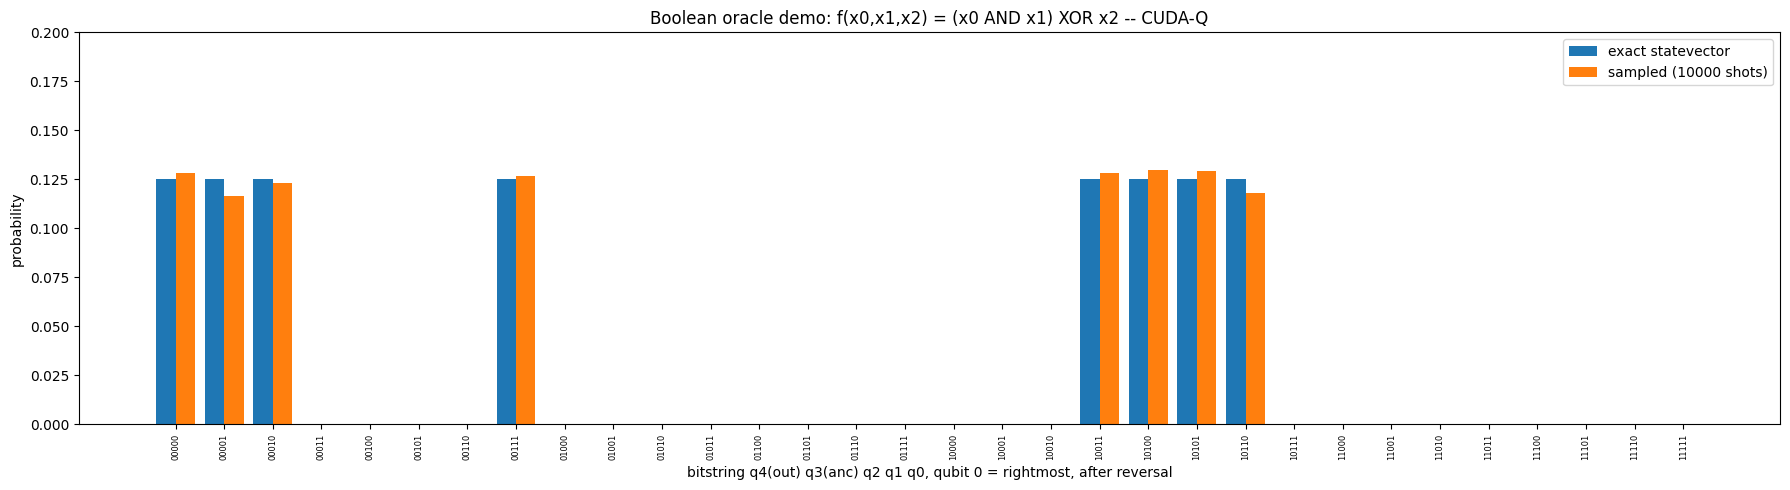

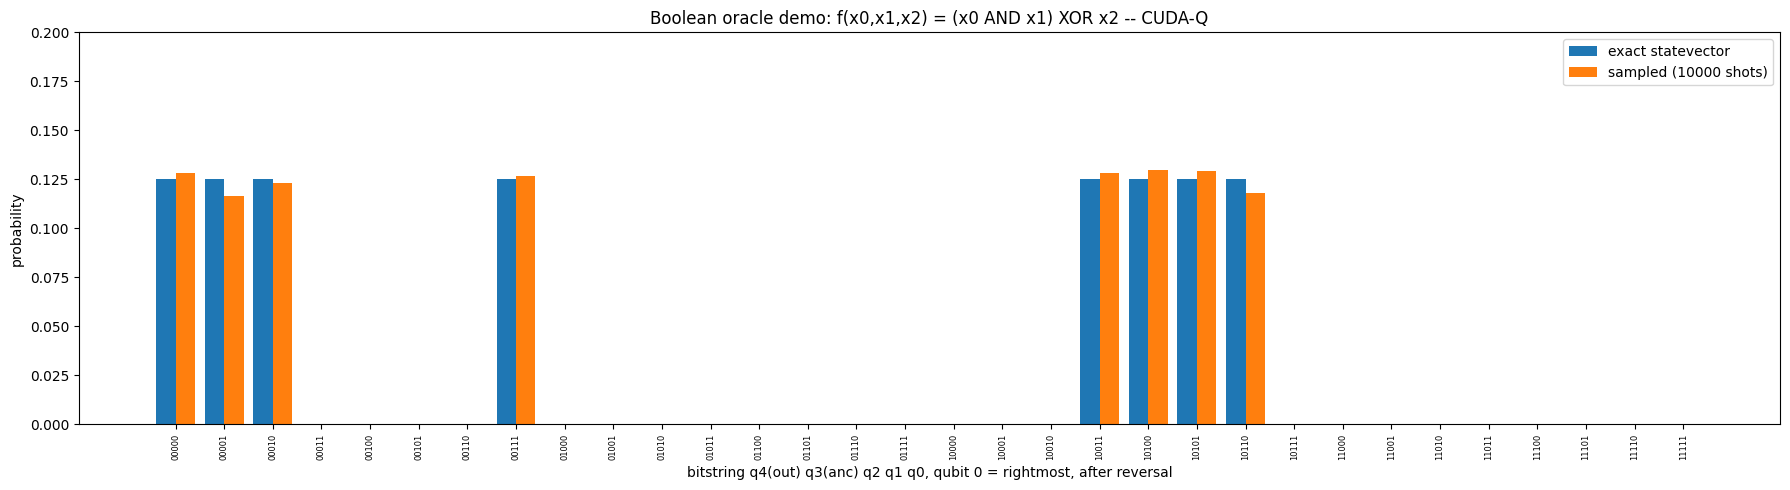

In [9]:
# Histogram: matplotlib bar chart, same style/axis ranges as the Qiskit notebook, saved to file
bitstrings_sorted = sorted(CUDAQ_PROBS_EXACT.keys())
exact_vals = [CUDAQ_PROBS_EXACT[b] for b in bitstrings_sorted]
sampled_vals = [CUDAQ_PROBS_SAMPLED[b] for b in bitstrings_sorted]

fig, ax = plt.subplots(figsize=(18, 5))
x = np.arange(len(bitstrings_sorted))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="exact statevector", color="#1f77b4")
ax.bar(x + width/2, sampled_vals, width, label=f"sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(bitstrings_sorted, rotation=90, fontsize=6)
ax.set_xlabel("bitstring q4(out) q3(anc) q2 q1 q0, qubit 0 = rightmost, after reversal")
ax.set_ylabel("probability")
ax.set_title("Boolean oracle demo: f(x0,x1,x2) = (x0 AND x1) XOR x2 -- CUDA-Q")
ax.set_ylim(0, 0.2)
ax.legend()
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig


In [10]:
# Resource counts (derived from the Python-side gate list, kept in sync with the kernel by construction)
from collections import Counter
gate_type_counts = Counter(g[0] for g in gatelist)
print("Gate counts:", dict(gate_type_counts))
print("Total gate count:", len(gatelist))


Gate counts: {'H': 3, 'MCX': 4}
Total gate count: 7


### Convention notes (plain text summary)

- **Bit-order convention:** qubit 0 = rightmost character. `cudaq.get_state()`'s NumPy
  array already matches this (no reversal applied); `cudaq.sample()`'s bitstring keys are
  the opposite, so reversal **is** applied there.
- **Global phase convention:** identical rule to the Qiskit notebook.
- **Basis ordering:** ascending binary order `|00000> ... |11111>` (5 qubits).
- **Why only 8 of 32 outcomes are possible:** same reason as the Qiskit notebook -- the
  oracle is a permutation deterministically pairing every input `x` with `ANCILLA=0` and
  `OUTPUT=f(x)`.


In [11]:
# Final result
CUDAQ_RESULT = {b: CUDAQ_PROBS_EXACT[b] for b in sorted(CUDAQ_PROBS_EXACT)}
print("CUDAQ_RESULT (nonzero entries) =")
for b, p in CUDAQ_RESULT.items():
    if p > 1e-9:
        print(f"  '{b}': {p:.6f}")


CUDAQ_RESULT (nonzero entries) =
  '00000': 0.125000
  '00001': 0.125000
  '00010': 0.125000
  '00111': 0.125000
  '10011': 0.125000
  '10100': 0.125000
  '10101': 0.125000
  '10110': 0.125000


In [12]:
# Diff-check block (run AFTER also running the Qiskit notebook and pasting its QISKIT_RESULT below)
HAND_COMPUTED_EXPECTED = {format(i, f'0{TOTAL_QUBITS}b'): 0.0 for i in range(2**TOTAL_QUBITS)}
for x in range(2**N_QUBITS):
    x0, x1, x2 = (x >> 0) & 1, (x >> 1) & 1, (x >> 2) & 1
    fx = f_boolean(x0, x1, x2)
    idx = x | (fx << OUTPUT_QUBIT)
    HAND_COMPUTED_EXPECTED[format(idx, f'0{TOTAL_QUBITS}b')] = 1/(2**N_QUBITS)

max_delta_vs_hand = max(abs(CUDAQ_RESULT[b] - HAND_COMPUTED_EXPECTED[b]) for b in CUDAQ_RESULT)
print("Max delta between CUDAQ_RESULT and hand-computed expected:", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# QISKIT_RESULT = { ... }  # <- paste the dict printed at the end of the Qiskit notebook here
# max_delta = max(abs(CUDAQ_RESULT[b] - QISKIT_RESULT[b]) for b in CUDAQ_RESULT)
# print("Max probability delta between QISKIT_RESULT and CUDAQ_RESULT:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q boolean-oracle results disagree beyond tolerance!"


Max delta between CUDAQ_RESULT and hand-computed expected: 5.551115123125783e-17
